# 4.4.- Clasificación de MNIST con Optimización de Hiperparámetros

En esta segunda parte haremos una **búsqueda aleatoria (Random Search)** con Keras Tuner para encontrar una arquitectura MLP sencilla pero efectiva sobre **MNIST**.

**Espacio de búsqueda (compacto):**
- Nº de capas ocultas: $\{1, 2\}$
- Unidades por capa: $\{128, 256, 384\}$
- Dropout: $\{0.0, 0.3, 0.5\}$
- Batch Normalization: $\{\text{sí}, \text{no}\}$
- Learning rate: $\{10^{-2}, 10^{-3}, 5\cdot 10^{-4}\}$
- Batch size: $\{64, 128\}$

**Objetivo:** maximizar `val_accuracy` con un presupuesto pequeño de *trials*.


In [1]:
# Importaciones básicas
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import keras_tuner as kt

# Configuración global de gráficos
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

# Semilla para reproducibilidad
np.random.seed(33)
keras.utils.set_random_seed(33)

## Carga y preprocesado de MNIST

- Normalizamos a $[0, 1]$ con $X \leftarrow X/255$  
- Aplanamos $28\times 28 \to 784$  
- One-hot de etiquetas (10 clases)

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28*28)
X_test  = X_test.reshape(-1, 28*28)

num_classes = 10
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test  = keras.utils.to_categorical(y_test, num_classes)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 784), (60000, 10), (10000, 784), (10000, 10))

## Definición del modelo parametrizable para el Random Search

En esta sección construimos una **plantilla de red neuronal MLP (Multilayer Perceptron)** capaz de adaptarse a distintos hiperparámetros durante la búsqueda automática con **Keras Tuner**.

La función `build_model(hp)` no define un modelo fijo, sino un **modelo parametrizable**:  
en cada prueba del *Random Search*, el objeto `hp` (de *HyperParameters*) elige una combinación distinta de valores, generando así diferentes arquitecturas y configuraciones de entrenamiento.

### Parámetros ajustables

1. **Número de capas ocultas (`n_hidden`)**  
   Determina la **profundidad** del modelo. Más capas implican mayor capacidad de aprendizaje, pero también un riesgo superior de sobreajuste.

2. **Número de neuronas por capa (`units_i`)**  
   Controla la **anchura** del modelo. Probamos valores típicos (128, 256, 384) para equilibrar capacidad y eficiencia.

3. **Batch Normalization (`use_bn_i`)**  
   Permite estabilizar y acelerar el entrenamiento normalizando las activaciones de cada mini-lote:
   $$
   \hat{x} = \frac{x - \mu_{\text{batch}}}{\sqrt{\sigma_{\text{batch}}^2 + \epsilon}}
   $$

4. **Dropout (`dropout_i`)**  
   Desactiva aleatoriamente un porcentaje de neuronas durante el entrenamiento para mejorar la generalización:
   $$
   P(\text{neurona apagada}) = \text{dropout}
   $$

5. **Tasa de aprendizaje (`learning_rate`)**  
   Define el tamaño del paso del optimizador **Adam**.  
   Se explorarán varios valores para encontrar un equilibrio entre velocidad y estabilidad del aprendizaje.

6. **Capas finales y activaciones**  
   - En las capas ocultas: `ReLU` → $f(x) = \max(0, x)$  
   - En la capa de salida: `softmax`, que convierte las salidas en probabilidades:
     $$
     \hat{y}_k = \frac{e^{z_k}}{\sum_j e^{z_j}}
     $$

### Propósito

Keras Tuner entrenará varias versiones del modelo con distintas combinaciones de estos parámetros.  
Al finalizar, identificará el conjunto que obtiene la **mayor `val_accuracy`**, es decir, el modelo con mejor capacidad de generalización.

In [3]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(784,)))

    n_hidden = hp.Int("n_hidden", 1, 2, step=1)
    for i in range(n_hidden):
        units = hp.Choice(f"units_{i}", values=[128, 256, 384])
        model.add(layers.Dense(units, activation="relu"))

        if hp.Boolean(f"use_bn_{i}", default=True):
            model.add(layers.BatchNormalization())

        dr = hp.Choice(f"dropout_{i}", values=[0.0, 0.3, 0.5])
        if dr > 0:
            model.add(layers.Dropout(dr))

    model.add(layers.Dense(10, activation="softmax"))

    lr = hp.Choice("learning_rate", values=[1e-2, 1e-3, 5e-4], default=1e-3)
    opt = keras.optimizers.Adam(learning_rate=lr)

    model.compile(optimizer=opt, loss="categorical_crossentropy", metrics=["accuracy"])
    return model

## Random Search

Presupuesto moderado:
- `max_trials = 8`
- `executions_per_trial = 1`

Usamos `validation_split=0.2` y *callbacks* ligeros para acelerar.

In [4]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=8,
    executions_per_trial=1,
    directory="artifacts",
    project_name="mnist_random_search"
)

tuner.search_space_summary()

light_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
]

tuner.search(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=hp_bs if (hp_bs := 128) else 128,  # explícito 128
    callbacks=light_callbacks,
    verbose=1
)

Reloading Tuner from artifacts\mnist_random_search\tuner0.json
Search space summary
Default search space size: 8
n_hidden (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 2, 'step': 1, 'sampling': 'linear'}
units_0 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 384], 'ordered': True}
use_bn_0 (Boolean)
{'default': True, 'conditions': []}
dropout_0 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.3, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.01, 0.001, 0.0005], 'ordered': True}
units_1 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 384], 'ordered': True}
use_bn_1 (Boolean)
{'default': True, 'conditions': []}
dropout_1 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.3, 0.5], 'ordered': True}


## Mejor configuración y reentrenamiento

- Recuperamos `best_hps`  
- Reentrenamos con *callbacks* más estrictos  
- Guardamos el **mejor modelo** como `mnist_rs_best.keras`

In [5]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Mejores hiperparámetros:")
for k in best_hps.values:
    print(f"  {k}: {best_hps.get(k)}")

best_model = tuner.hypermodel.build(best_hps)

strong_callbacks = [
    callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    callbacks.ModelCheckpoint("mnist_rs_best.keras", monitor="val_loss", save_best_only=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)
]

history = best_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=best_hps.get("batch_size") if "batch_size" in best_hps.values else 128,
    callbacks=strong_callbacks,
    verbose=1
)

Mejores hiperparámetros:
  n_hidden: 1
  units_0: 256
  use_bn_0: False
  dropout_0: 0.3
  learning_rate: 0.001
Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8068 - loss: 0.6588 - val_accuracy: 0.9505 - val_loss: 0.1813 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9419 - loss: 0.2005 - val_accuracy: 0.9616 - val_loss: 0.1343 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9580 - loss: 0.1463 - val_accuracy: 0.9663 - val_loss: 0.1114 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9656 - loss: 0.1173 - val_accuracy: 0.9710 - val_loss: 0.0969 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9713 - loss: 0.0977 - val_accuracy: 0.9730 - val_loss: 0.0888 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9754 - loss: 0.0816 - val_accuracy: 0.9740 - val_loss: 0.0853 

## Evolución de la pérdida y la exactitud

Comparamos *loss* y *accuracy* del modelo ajustado, y mostramos las curvas de entrenamiento/validación.

MNIST (Random Search) — Loss test: 0.0603 | Acc test: 0.9830


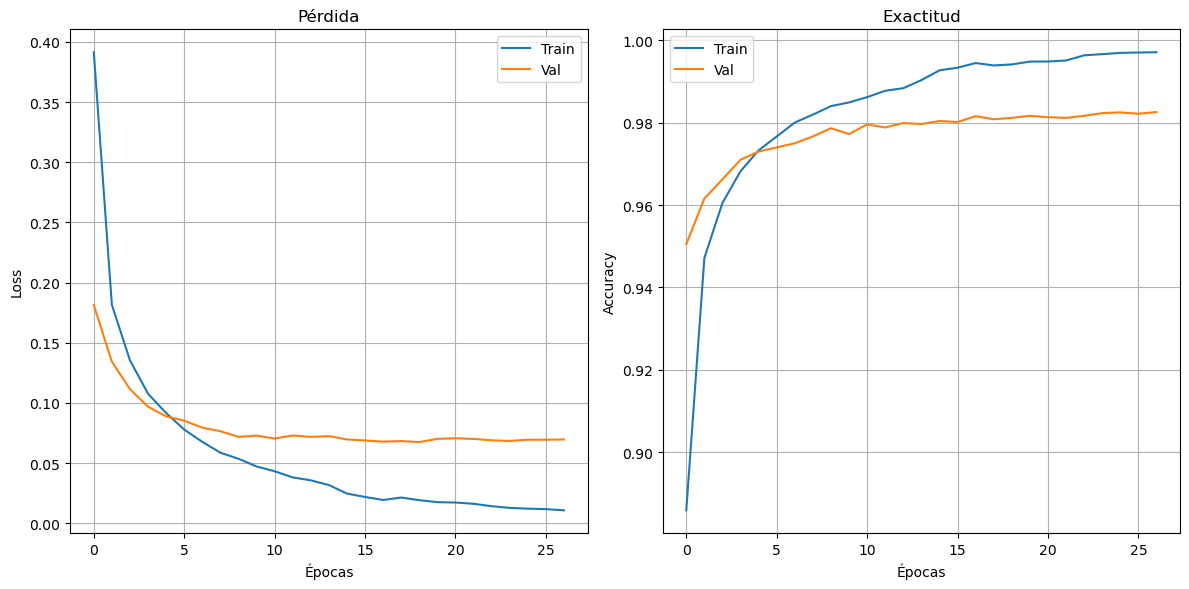

In [6]:
loaded = keras.models.load_model("mnist_rs_best.keras")
test_loss, test_acc = loaded.evaluate(X_test, y_test, verbose=0)
print(f"MNIST (Random Search) — Loss test: {test_loss:.4f} | Acc test: {test_acc:.4f}")

# Curvas rápidas
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(history.history["loss"], label="Train")
ax[0].plot(history.history["val_loss"], label="Val")
ax[0].set_title("Pérdida (Loss)")
ax[0].set_xlabel("Épocas"); ax[0].set_ylabel("Loss"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="Train")
ax[1].plot(history.history["val_accuracy"], label="Val")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Épocas"); ax[1].set_ylabel("Accuracy"); ax[1].legend()

plt.tight_layout()
plt.show()